# A. EDA complémentaire

**Contributeurs :** Cécile · **Date :** 27/10/2026

Analyses réalisées après le premier rapport. Équipements : nouvelle source, la BPE en évolution de l'Insee (nombre d'équipements par bassin de vie en 2015, 2020 et 2025), à la place de la table de présence par commune.

## 0. Chargement

In [12]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
import re

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

# config.py se trouve à la racine du projet
racine = Path.cwd()
while not (racine / "config.py").exists() and racine != racine.parent:
    racine = racine.parent
sys.path.insert(0, str(racine))
from config import DATA_RAW, DATA_OUT

pd.set_option("display.max_columns", None)

fichier = DATA_OUT / "fe_cible_toutes_sources_sbv_encodee.parquet"
df = pd.read_parquet(fichier)

if "annee_sbv_typebien" not in df.columns:      # la clé peut être dans l'index
    df = df.reset_index()

TARGET = "prix_m2_med"

In [14]:
# La clé a la forme  <annee>_<sbv>_<typebien>  ; sbv peut contenir un suffixe _N (ex. 06029_1)
key = df["annee_sbv_typebien"]
df["sbv"] = key.str.split("_", n=1).str[1].str.rsplit("_", n=1).str[0]
df["typebien"] = key.str.rsplit("_", n=1).str[1]
df["dept"] = df["sbv"].str[:2]

**Constat :** la clé annee_sbv_typebien encode trois informations, et certaines zones ont un suffixe (06029_1, 241 zones).

**Interprétation :** sbv n’est pas un code commune pur, c’est un découpage de zone. Une commune peut donc être subdivisée.

**Conséquence :** il faut parser avec split(n=1) puis rsplit(n=1), pas un simple split("_"). Pour une jointure avec une source externe par code INSEE, il faudra gérer ces suffixes.

## 1. Audit rapide

**Contributeurs :** Gabrielle · **Date :** 30/10/2026

In [15]:
# Structure

print("shape :", df.shape)
print(df.dtypes.value_counts().to_string())
print(df.head(3).T.head(15).to_string())

shape : (43604, 61)
float64    46
int64      11
object      3
str         1
                                              0                       1                  2
annee_sbv_typebien            2014_01004_maison  2014_01004_appartement  2015_01004_maison
annee                                      2014                    2014               2015
maison                                        1                       0                  1
appartement                                   0                       1                  0
nb_biens                                    368                      59                379
nb_ventes_n1                                NaN                     NaN              368.0
prix_m2_med                              1691.0                  1836.0             1667.0
nb_vols_vehicules                           NaN                     NaN                NaN
nb_vols_violents                            NaN                     NaN                NaN
nb_vols_sans_v

**Constat :** 43 604 × 58, presque tout en float, une seule colonne texte (la clé).

**Interprétation :** le fichier est déjà un jeu de features numériques, prêt à modéliser.

**Conséquence :** la clé n’est pas une feature, elle sert d’identifiant. sbv, typebien et dept sont dérivés dans le script, pas dans le fichier d’origine.

In [16]:
#clé et panel

print("doublons clé        :", key.duplicated().sum())
print("zones (sbv)         :", df["sbv"].nunique(), "| départements :", df["dept"].nunique())
print("années              :", sorted(df["annee"].unique()))
print("lignes par année    :", df.groupby("annee").size().to_dict())
print("lignes par typebien :", df["typebien"].value_counts().to_dict())
obs = df.groupby(["sbv", "typebien"]).size()
print("obs par zone x type :", obs.describe()[["min", "50%", "max"]].to_dict())
print("annee == annee de la clé :", (key.str[:4].astype(int) == df["annee"]).all())

doublons clé        : 0
zones (sbv)         : 1817 | départements : 93
années              : [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
lignes par année    : {2014: 3632, 2015: 3634, 2016: 3634, 2017: 3634, 2018: 3634, 2019: 3634, 2020: 3634, 2021: 3634, 2022: 3632, 2023: 3634, 2024: 3634, 2025: 3634}
lignes par typebien : {'maison': 21802, 'appartement': 21802}
obs par zone x type : {'min': 11.0, '50%': 12.0, 'max': 12.0}
annee == annee de la clé : True


**Constat :** 0 doublon, 1 817 zones × 2 types × 12 ans, 11 ou 12 observations par zone × type.

**Interprétation :** c’est un panel équilibré, avec les mêmes zones suivies sur toute la période.

**Conséquence :** un split aléatoire est à proscrire, car la même zone se retrouverait en train et en test. Il faut un split temporel, par exemple test sur 2024-2025, ou groupé par zone. On peut aussi exploiter la dimension panel avec des lags et des effets zone.

In [25]:
# valeurs manquantes
na = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print(na[na > 0].to_string())

taux3_cambriolages                 41.7
taux3_vols_violents                41.7
taux3_vols_sans_violence           41.7
taux3_destructions                 41.7
taux3_vols_vehicules               41.7
taux3_violences_intrafamiliales    41.7
taux3_violences_sexuelles          41.7
taux3_stupefiants                  41.7
nb_stupefiants                     25.0
nb_vols_sans_violence              25.0
insee_pop                          25.0
nb_violences_intrafamiliales       25.0
nb_destructions                    25.0
taux1_vols_violents                25.0
taux1_vols_vehicules               25.0
part_indicateurs_estimes           25.0
insee_log                          25.0
taux1_cambriolages                 25.0
taux1_vols_sans_violence           25.0
taux1_destructions                 25.0
nb_violences_sexuelles             25.0
taux1_stupefiants                  25.0
nb_cambriolages                    25.0
annee_faits                        25.0
taux1_violences_sexuelles          25.0


**Constat :** la délinquance, insee_* et annee_faits sont à 25 % de nulls, les taux3_* à 41,7 %, la cible à 6 %.

**Interprétation :** la majorité des nulls sont de l’indisponibilité historique, pas du hasard.

**Conséquence :** une imputation par la moyenne serait trompeuse. Choisis entre restreindre l’entraînement aux années complètes (2019+ pour les taux3_*), ou garder toutes les années avec des modèles tolérant les NaN (LightGBM). Dans ce cas, les taux3_* sont de toute façon quasi redondants avec les taux1_*.

In [ ]:
#Nulls par année (% ) — colonnes représentatives"
cols_na = [TARGET, "nb_ventes_n1", "nb_vols_vehicules", "taux1_cambriolages",
           "taux3_cambriolages", "insee_pop"]
print(df.groupby("annee")[cols_na].apply(lambda g: g.isna().mean() * 100).round(0).T.to_string())

**Constat :** les nulls sont en blocs par année : délinquance absente 2014-2016, taux3_* absents 2014-2018, nb_ventes_n1 absent en 2014.

**Interprétation :** c’est un effet de fenêtre temporelle de calcul (moyenne glissante sur 3 ans, décalage N-1), pas un défaut de qualité de la donnée.

**Conséquence :** les années récentes sont plus riches en features que les anciennes. Le modèle voit donc des distributions différentes selon l’année, ce qui pèse sur la comparabilité train/test.

In [ ]:
# Cible : nulls vs nb_biens"
print("prix nul & nb_biens > 0  :", (df[TARGET].isna() & (df["nb_biens"] > 0)).sum())
print("prix nul & nb_biens == 0 :", (df[TARGET].isna() & (df["nb_biens"] == 0)).sum())
print("part des lignes avec nb_biens < 5 :", round((df["nb_biens"] < 5).mean(), 3))

**Constat :** tous les nulls de prix_m2_med (2 610) correspondent à nb_biens == 0, et 15,5 % des lignes ont moins de 5 ventes.

**Interprétation :** le prix est absent parce qu’il n’y a pas de vente, ce n’est pas une donnée perdue. Avec peu de ventes, la médiane est très bruitée.

**Conséquence :** exclus les lignes sans prix de l’entraînement. Envisage un seuil minimal de ventes, ou une pondération par nb_biens, pour éviter d’apprendre sur du bruit. Un modèle ne pourra jamais prédire un prix là où il n’y a pas de marché.

In [26]:
# distribution valeurs numériques
num_cols = [c for c in df.select_dtypes("number").columns if c not in ("maison", "appartement")]
desc = df[num_cols].describe(percentiles=[0.01, 0.5, 0.99]).T
print(desc[["count", "mean", "std", "min", "1%", "50%", "99%", "max"]].round(2).to_string())

                                   count      mean        std       min        1%       50%        99%         max
annee                            43604.0   2019.50       3.45   2014.00   2014.00   2019.50    2025.00     2025.00
nb_biens                         43604.0    221.43    1185.06      0.00      0.00     88.00    1959.97    70042.00
nb_ventes_n1                     39972.0    221.71    1193.65      0.00      0.00     88.00    1961.29    70042.00
prix_m2_med                      40994.0   2022.13    1562.37     53.00    455.00   1673.00    8613.07    42581.00
nb_vols_vehicules                32704.0    206.05    1585.00      0.00      3.90     48.85    2149.88    71558.56
nb_vols_violents                 32704.0     40.56     473.84      0.00      0.00      3.02     757.94    27057.55
nb_vols_sans_violence            32704.0    343.44    2420.62      0.00      7.76     64.41    6218.70    97663.62
nb_cambriolages                  32704.0    116.28     737.55      0.00      4.4

**Constat :** les volumes (nb_*, insee_pop, nb_equip_*) ont des queues très lourdes (médiane de 88 pour nb_biens, max de 70 042). Les taux* sont plus calmes, sauf vols_sans_violence (max 675) et stupefiants (max 176).

**Interprétation :** les maxima viennent des grandes villes comme Paris, pas d’erreurs de saisie. Les pics des taux* correspondent plutôt à des zones à faible population, où un petit nombre de faits donne un taux élevé.

**Conséquence :** ne supprime pas ces outliers, ils sont réels. Utilise des transformations log pour les volumes, et regarde la robustesse des taux* dans les zones peu peuplées.

In [ ]:
# distribution asymétrique des variables numériques
skew = df[num_cols].skew().sort_values(ascending=False)
print(skew[skew > 3].round(1).to_string())
print(f"\n{TARGET}: skew brut = {df[TARGET].skew():.2f} | skew log = {np.log(df[TARGET]).skew():.2f}")

**Constat :** prix_m2_med a un skew de 5,98, qui tombe à 0,23 après log.

**Interprétation :** la distribution est quasi log-normale, ce qui est typique des prix immobiliers.

**Conséquence :** modélise log(prix_m2_med). Tu travailles alors en erreur relative, pas en euros, et Paris ne domine plus la fonction de perte. Applique le même traitement aux variables de volume très asymétriques.

# B. Relations entre les variables

### B1. La cible dans le temps

In [19]:
print(df.pivot_table(index="typebien", columns="annee", values=TARGET, aggfunc="median").round(0).to_string())

annee          2014    2015    2016    2017    2018    2019    2020    2021    2022    2023    2024    2025
typebien                                                                                                   
appartement  1534.0  1504.0  1488.0  1500.0  1504.0  1515.0  1571.0  1684.0  1855.0  1891.0  1905.0  1932.0
maison       1516.0  1500.0  1514.0  1543.0  1574.0  1596.0  1686.0  1813.0  1983.0  1990.0  1937.0  1960.0


**Constat :** prix plats de 2014 à 2019 (~1 500 €/m²), puis ~+25 % entre 2020 et 2022, avec des maisons au-dessus des appartements depuis 2018.

**Interprétation :** il y a une rupture de marché post-2020 (effet post-Covid, taux bas), et le type de bien change le comportement du prix.

**Conséquence :** annee sera un prédicteur dominant, mais risqué. Un modèle à base d’arbres ne extrapole pas hors de la plage de prix vue à l’entraînement. Pour une prévision hors période, mieux vaut prédire une variation (log du ratio au prix précédent de la zone) ou déflater par un indice national. Garde typebien en interaction ou entraîne deux modèles.

In [20]:
# top 10 départements
print(df.groupby("dept")[TARGET].median().sort_values(ascending=False).head(10).round(0).to_string())

dept
75    10526.0
06     3718.0
74     3674.0
2A     3550.0
13     3220.0
83     3114.0
95     2891.0
78     2870.0
91     2814.0
2B     2772.0


**Constat :** Paris (75) à ~10 500 €/m², loin devant le suivant (06 à ~3 700).

**Interprétation :** la distribution géographique est très inégale, avec des zones chères (Paris, Côte d’Azur, Haute-Savoie, Corse) et un gros du territoire entre 1 000 et 2 500 €.

**Conséquence :** le département ou la localisation sera une information majeure. Fais attention à un dept encodé en entier (il n’est pas ordinal) et à la cardinalité (93 valeurs) : préfère un target encoding sur le passé, ou des coordonnées géographiques.

### B2. Corrélations

In [21]:
# corrélation de spearman avec la cible, le top 15 uniquement
num = df[num_cols]
corr_t = num.corr(method="spearman")[TARGET].drop(TARGET).dropna()
print(corr_t.reindex(corr_t.abs().sort_values(ascending=False).index).head(15).round(2).to_string())

taux_vacance                 -0.67
part_avant1946               -0.63
anciennete_moyenne           -0.63
niveau_vie_median             0.62
part_2006_2019                0.50
part_logements_taux_impute   -0.46
nb_equip_transports           0.44
part_apparts                  0.43
taux_vacance_complete        -0.41
part_suroccupes               0.37
part_moins40m2                0.37
taux3_vols_vehicules          0.35
taux3_vols_violents           0.35
taux1_vols_vehicules          0.34
nb_vols_violents              0.34


**Constat :** les plus fortes sont taux_vacance (−0,67), part_avant1946 et anciennete_moyenne (−0,63), niveau_vie_median (+0,62). La délinquance est à ~+0,35.

**Interprétation :** les prix suivent le dynamisme de la zone (peu de vacance, parc récent, revenus élevés). La corrélation positive avec la délinquance reflète un effet d’urbanité (grandes villes denses = plus chères et plus de faits enregistrés), pas un effet causal.

**Conséquence :** ne lis pas la délinquance comme un facteur qui fait monter les prix. Contrôle la densité, et utilise une importance de variables par permutation ou SHAP plutôt que les corrélations brutes.

In [22]:
# les paires redondantes cad corrélation > 0.95
cm = num.drop(columns=TARGET).corr(method="spearman").abs()
upper = cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1))
pairs = upper.stack()
print(pairs[pairs > 0.95].sort_values(ascending=False).round(3).to_string())

annee              annee_faits           1.000
                   annee_ventes          1.000
annee_faits        annee_ventes          1.000
insee_log          log_nb_logements      0.999
insee_pop          nb_menages_fiscaux    0.995
nb_biens           nb_ventes_n1          0.989
nb_equip_services  log_nb_logements      0.952


**Constat :** annee / annee_faits / annee_ventes (1,0), insee_log / log_nb_logements (0,999), insee_pop / nb_menages_fiscaux (0,995), nb_biens / nb_ventes_n1 (0,989).

**Interprétation :** ce sont les mêmes informations sous différents noms, ou des décalages fixes.

**Conséquence :** retire les doublons. Pas d’impact sur la performance d’un arbre, mais pour un modèle linéaire ou des importances lisibles, c’est utile.

In [23]:
# comparaison de insee_pop et insee_log avec d'autres variables avec lesquelles elles sont corrélées
print("insee_pop vs nb_menages_fiscaux  :",
      round(df[["insee_pop", "nb_menages_fiscaux"]].corr(method="spearman").iloc[0, 1], 4))
print("insee_log vs log_nb_logements    :",
      round(df[["insee_log", "log_nb_logements"]].corr(method="spearman").iloc[0, 1], 4))
print("nulls insee_pop / nb_menages_fiscaux :",
      f"{df['insee_pop'].isna().mean():.1%} / {df['nb_menages_fiscaux'].isna().mean():.1%}")
print("nulls insee_log / log_nb_logements   :",
      f"{df['insee_log'].isna().mean():.1%} / {df['log_nb_logements'].isna().mean():.1%}")

insee_pop vs nb_menages_fiscaux  : 0.9945
insee_log vs log_nb_logements    : 0.9994
nulls insee_pop / nb_menages_fiscaux : 25.0% / 0.0%
nulls insee_log / log_nb_logements   : 25.0% / 0.0%


**Constat :** insee_pop et insee_log ont 25 % de nulls, nb_menages_fiscaux et log_nb_logements aucun.

**Interprétation :** les équivalents font le même travail sans les trous.

**Conséquence :** supprime insee_pop et insee_log, et garde les deux autres. Tu gagnes 14 % de complétude sur ces variables.

### B2. graphes


Graphique enregistré : eda_apercu.png


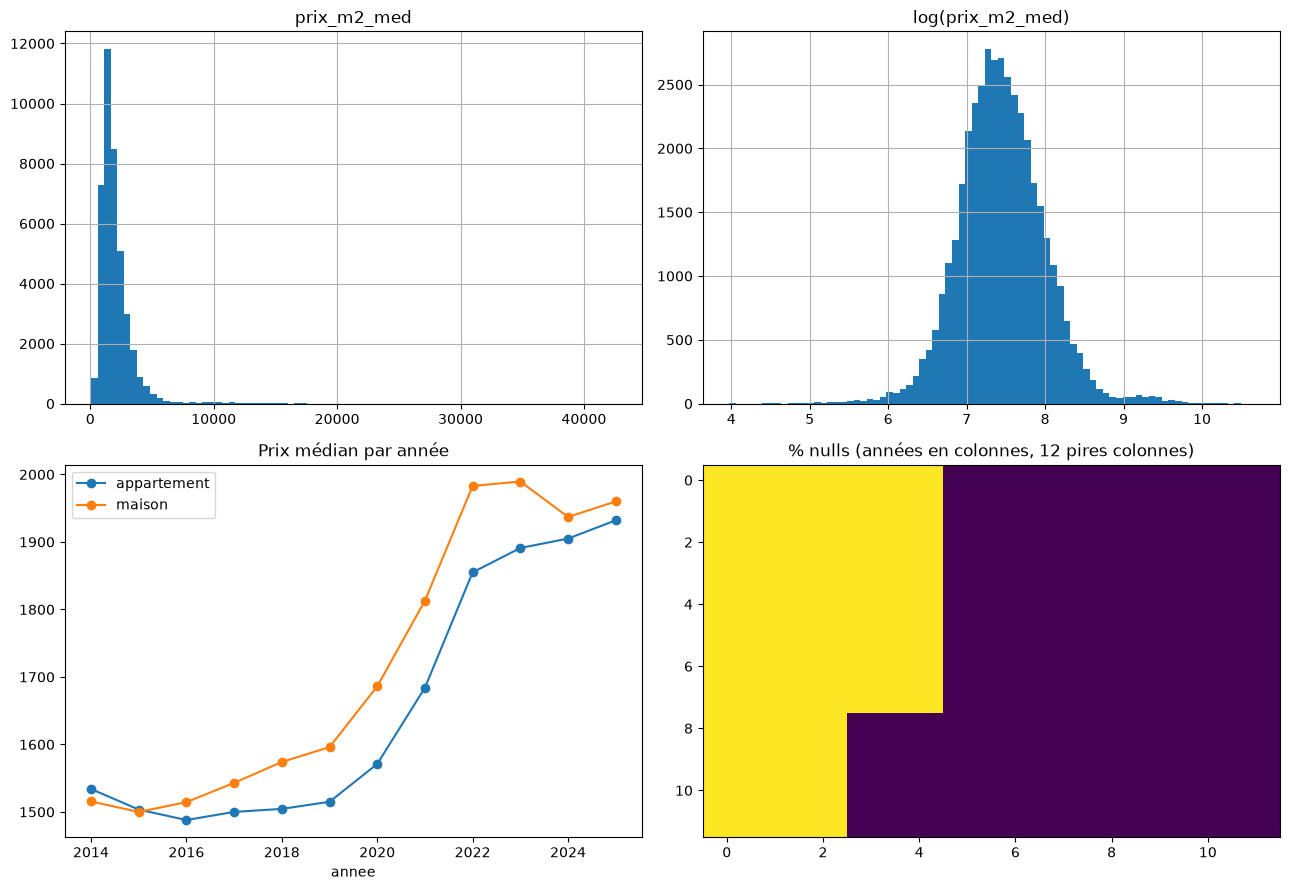

In [24]:
try:
    import matplotlib.pyplot as plt
 
    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    df[TARGET].hist(bins=80, ax=ax[0, 0]); ax[0, 0].set_title(f"{TARGET}")
    np.log(df[TARGET]).hist(bins=80, ax=ax[0, 1]); ax[0, 1].set_title(f"log({TARGET})")
    for t, g in df.groupby("typebien"):
        g.groupby("annee")[TARGET].median().plot(ax=ax[1, 0], marker="o", label=t)
    ax[1, 0].set_title("Prix médian par année"); ax[1, 0].legend()
    (df.isna().groupby(df["annee"]).mean() * 100).loc[:, na[na > 0].index[:12]].T.pipe(
        lambda m: ax[1, 1].imshow(m.values, aspect="auto", cmap="viridis"))
    ax[1, 1].set_title("% nulls (années en colonnes, 12 pires colonnes)")
    plt.tight_layout()
    plt.savefig("eda_apercu.png", dpi=120)
    print("\nGraphique enregistré : eda_apercu.png")
except ImportError:
    print("\n(matplotlib absent : graphiques ignorés)")

**Constat :** distribution brute vs log, tendance par type, carte des nulls par année.

**Interprétation :** c’est un contrôle visuel qui confirme les points 6, 8 et 9.

**Conséquence :** à regarder avant de figer les transformations.

# C. Synthèse

Périmètre : 43 604 lignes × 58 colonnes, panel équilibré de 1 817 sous-bassins × 2 types de bien × 12 ans (2014-2025). La cible retenue est prix_m2_med.

#	Constat majeur	Preuve	Conséquence projet	Action
1	Panel équilibré et clé propre	0 doublon de clé ; 11 à 12 observations par sous-bassin × type	Les observations d'une même zone sont liées dans le temps	Split temporel (ex. test 2024-2025) ou groupé par zone, jamais aléatoire
2	La cible est log-normale	Skew de 5,98 en brut contre 0,23 après log ; médiane 1 673 €, max 42 581 €	Paris et les zones chères dominent une perte en euros	Modéliser log(prix_m2_med)
3	6 % de cible manquante, uniquement là où il n'y a pas de vente	2 610 lignes à nb_biens == 0, toutes avec prix nul, 0 prix nul avec nb_biens > 0	Le prix n'existe pas, il n'est pas imputable	Exclure ces lignes de l'entraînement
4	Le seuil de 20 ventes tient au niveau sous-bassin, pas au niveau ligne	Min de 32 ventes par sous-bassin (tous types et années cumulés) ; 28,1 % des lignes ≤ 20 ventes	Le bruit sur la cible reste fort dans les cellules à faible volume	Garder le seuil amont ; découper l'erreur par tranche de nb_biens à l'évaluation
5	Les nulls sont structurels et par blocs d'années	Délinquance et insee_* absents 2014-2016 (25 %) ; taux3_* absents 2014-2018 (41,7 %) ; nb_ventes_n1 absent en 2014	Les années anciennes ont moins de features que les récentes	Restreindre les années, ou utiliser un modèle tolérant les NaN (LightGBM), sans imputer par la moyenne
6	Rupture de marché après 2020	Médiane ~1 500 €/m² en 2014-2019, puis ~1 950 € en 2022-2025 (+25 %)	annee est un prédicteur fort mais risqué : un arbre n'extrapole pas hors de sa plage de prix	Tester la prédiction d'une variation par rapport au prix précédent de la zone, ou un déflateur
7	Les prix sont portés par la dynamique locale, pas par la délinquance	Spearman : taux_vacance −0,67, part_avant1946 −0,63, niveau_vie_median +0,62 ; délinquance ~+0,35	La corrélation délinquance-prix reflète l'urbanité, pas une causalité	Interpréter avec SHAP ou l'importance par permutation, pas par corrélations brutes
8	Redondances fortes entre variables	insee_log / log_nb_logements 0,999 ; insee_pop / nb_menages_fiscaux 0,995 ; nb_biens / nb_ventes_n1 0,989 ; annee_faits et annee_ventes = annee décalée	Information dupliquée, avec 25 % de nulls sur insee_* contre 0 % sur leurs équivalents	Supprimer insee_pop, insee_log, annee_faits, annee_ventes, et probablement nb_ventes_n1
9	Queues très lourdes sur les volumes	nb_biens : médiane 88, max 70 042 ; insee_pop max 8,5 M ; pics sur taux*_vols_sans_violence (675)	Les valeurs extrêmes sont réelles (grandes villes, petites zones), pas des erreurs	Ne pas supprimer les outliers ; passer les volumes en lo

## Variables candidates pour la modélisation

Variable	Justification rapide
maison, appartement	Déjà encodées ; le type de bien change le niveau de prix (maisons au-dessus depuis 2018)
annee	Capte la dérive du marché, surtout après 2020 ; à surveiller pour l'extrapolation
taux_vacance	Meilleur signal univarié (ρ = −0,67), proxy d'attractivité de la zone
taux_vacance_complete	ρ = −0,41, 24 nulls ; à garder seulement si elle apporte du signal en plus de taux_vacance
niveau_vie_median	ρ = +0,62, 0 null ; capacité d'achat locale
part_avant1946	ρ = −0,63 ; âge du parc
anciennete_moyenne	ρ = −0,63 ; proche de part_avant1946, à tester si l'une des deux suffit
part_2006_2019	ρ = +0,50 ; part de logements récents
part_apparts	ρ = +0,43 ; caractère urbain du parc
part_moins40m2, part_suroccupes	ρ ≈ +0,37 ; densité et tension du parc
part_rsec, part_sans_voiture, part_parking, taille_menage	Structure du parc et des ménages, complètes (0 null) ; à garder si le modèle les valorise
log_nb_logements	Taille de la zone, déjà en log et sans null ; remplace insee_log
nb_menages_fiscaux	Taille de la zone, sans null ; à passer en log ; remplace insee_pop
nb_biens	Volume du marché et indicateur de fiabilité du prix ; à passer en log, à vérifier qu'il est disponible au moment de prédire
nb_equip_transports, nb_equip_commerces, nb_equip_sante, nb_equip_sports, nb_equip_tourisme	Niveau d'équipement (ρ = +0,44 pour les transports) ; à passer en log
nb_equip_services	ρ = 0,95 avec log_nb_logements ; à retirer ou à ramener au nombre de logements
taux1_vols_vehicules, taux1_vols_violents, taux1_vols_sans_violence, taux1_cambriolages, taux1_destructions, taux1_stupefiants, taux1_violences_intrafamiliales, taux1_violences_sexuelles	Déjà ramenés à la population ; disponibles dès 2017, avec des NaN avant ; à garder pour l'effet marginal
part_logements_taux_impute, part_indicateurs_estimes	Indicateurs de qualité des données ; part_logements_taux_impute a ρ = −0,46, à vérifier si c'est un proxy rural plutôt qu'un vrai signal

À exclure : insee_pop, insee_log, annee_faits, annee_ventes, nb_ventes_n1, les taux3_* (redondants avec les taux1_*, 41,7 % de nulls) et les nb_* de délinquance (proxys de taille de zone, alors que les taux1_* sont normalisés).